# Cowboy Cigarettes: A Time Series Investigation

This Tier 3 case study uses monthly sales from January 1949 through December 1960 to reconstruct the likely direction of sales in the early 1960s. The analysis covers data validation, decomposition, stationarity testing, ARIMA model comparison, holdout evaluation, and a three-year forecast.

The main question is whether sales most likely **increased, decreased, or stayed approximately the same** after 1960.

## 1. Load and inspect the data

The supplied sales column contains a fixed one-million-unit baseline. I retain the original values for reporting. For logarithmic modeling, I subtract that fixed baseline first so the transform describes changes in the varying portion of the series rather than compressing them against a very large constant.

In [1]:
from pathlib import Path
import itertools
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tools.sm_exceptions import ConvergenceWarning, InterpolationWarning
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import kpss

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=InterpolationWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.titleweight"] = "bold"

DATA_PATH = Path("CowboyCigsData.csv")
BASELINE = 1_000_000

In [2]:
cig_data = pd.read_csv(DATA_PATH)
print(f"Rows: {len(cig_data):,}")
display(cig_data.head())
display(cig_data.tail())

Rows: 144


,Unnamed: 0,Time,#CigSales
0,0,1949-01,1000112
1,1,1949-02,1000118
2,2,1949-03,1000132
3,3,1949-04,1000129
4,4,1949-05,1000121


,Unnamed: 0,Time,#CigSales
139,139,1960-08,1000606
140,140,1960-09,1000508
141,141,1960-10,1000461
142,142,1960-11,1000390
143,143,1960-12,1000432


In [3]:
print("Columns:", cig_data.columns.tolist())
print("\nData types:")
display(cig_data.dtypes.to_frame("dtype"))
print("\nMissing values:")
display(cig_data.isna().sum().to_frame("missing"))

Columns: ['Unnamed: 0', 'Time', '#CigSales']

Data types:


,dtype
Unnamed: 0,int64
Time,str
#CigSales,int64



Missing values:


,missing
Unnamed: 0,0
Time,0
#CigSales,0


## 2. Clean and convert the series

The unnamed CSV index is removed, `Time` is renamed to `Month`, and the dates become a monthly `DatetimeIndex`. The cleaned data contains 144 consecutive months and no missing sales values.

In [4]:
cig_data = cig_data.drop(columns=["Unnamed: 0"]).rename(
    columns={"Time": "Month", "#CigSales": "CigSales"}
)
cig_data["Month"] = pd.to_datetime(cig_data["Month"])
cig_data = cig_data.set_index("Month").asfreq("MS")

y = cig_data["CigSales"].astype(float)
excess_sales = y - BASELINE

print(f"Date range: {y.index.min():%B %Y} to {y.index.max():%B %Y}")
print(f"Monthly frequency: {y.index.freqstr}")
print(f"Missing months: {y.isna().sum()}")
display(y.describe().to_frame("CigSales"))

Date range: January 1949 to December 1960
Monthly frequency: MS
Missing months: 0


,CigSales
count,1.440000e+02
mean,1.000280e+06
std,1.199663e+02
min,1.000104e+06
25%,1.000180e+06
50%,1.000266e+06
75%,1.000360e+06
max,1.000622e+06


## 3. Explore trend and seasonality

Sales rise over the full period, while a repeating annual pattern produces higher summer sales and lower winter sales. The seasonal swings also become larger as the level rises, which supports a multiplicative decomposition.

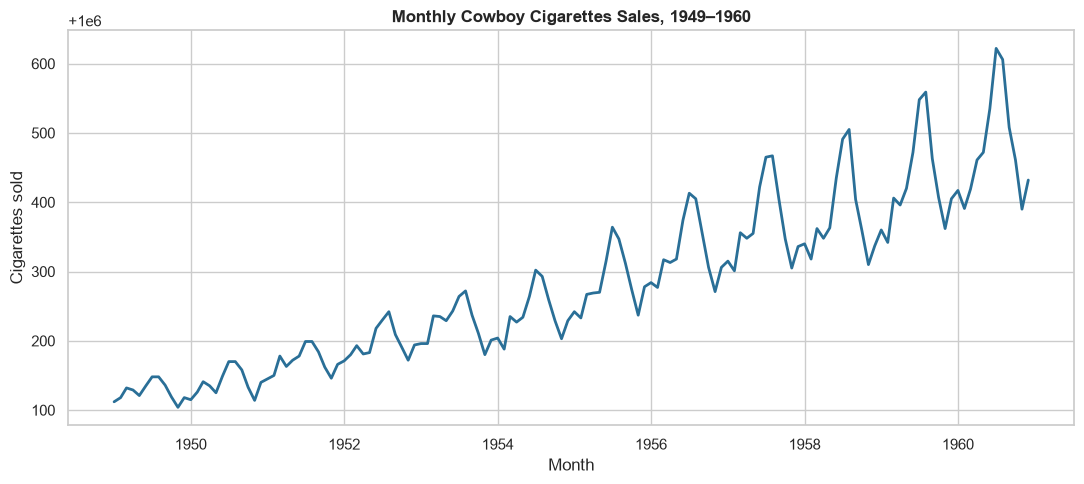

In [5]:
fig, ax = plt.subplots()
ax.plot(y.index, y, color="#2A6F97", linewidth=2)
ax.set(title="Monthly Cowboy Cigarettes Sales, 1949–1960", xlabel="Month", ylabel="Cigarettes sold")
ax.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

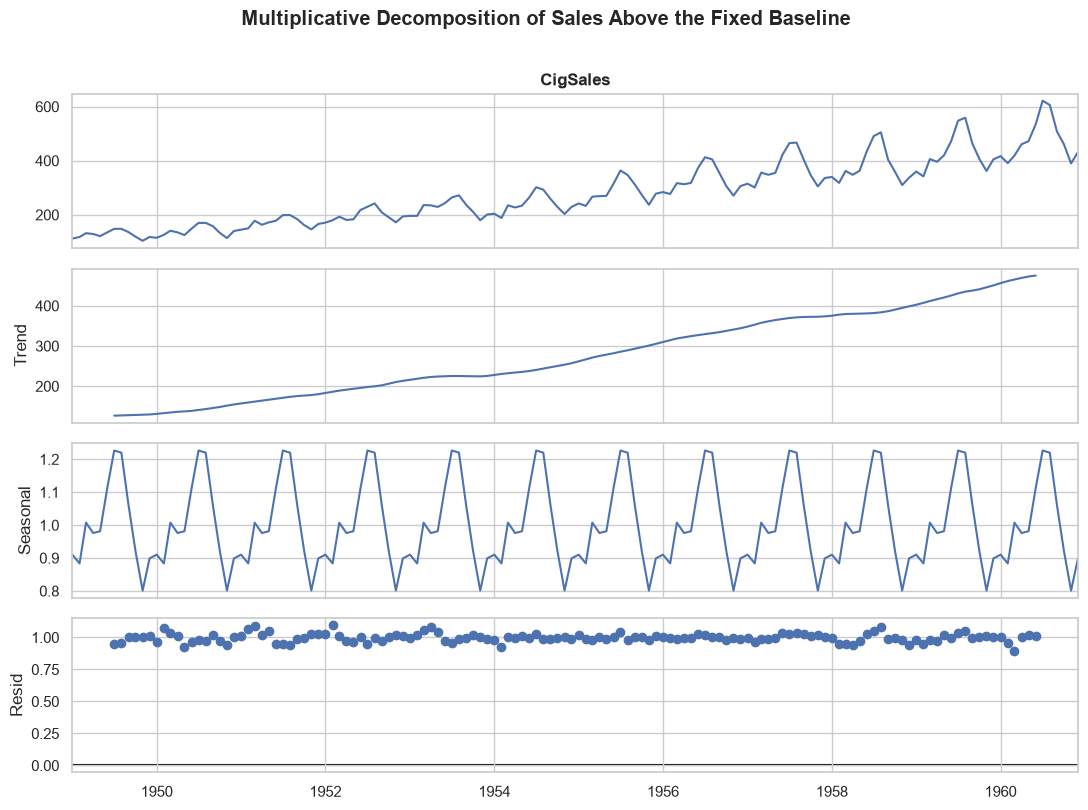

In [6]:
decomposition = seasonal_decompose(excess_sales, model="multiplicative", period=12)
fig = decomposition.plot()
fig.set_size_inches(11, 8)
fig.suptitle("Multiplicative Decomposition of Sales Above the Fixed Baseline", y=1.01, fontweight="bold")
plt.tight_layout()
plt.show()

The decomposition separates the upward trend from a stable month-of-year pattern. Residual variation remains, so forecasts should be treated as estimates rather than exact sales totals.

## 4. Test for stationarity

For the KPSS test, the null hypothesis is that the series is stationary. A p-value below 0.05 is evidence against stationarity. I log the varying portion of sales to stabilize its variance and then difference it once to remove the trend.

In [7]:
def kpss_result(series, label):
    statistic, p_value, lags, _ = kpss(series.dropna(), regression="c", nlags="auto")
    return {
        "series": label,
        "KPSS statistic": statistic,
        "p-value": p_value,
        "lags": lags,
        "stationary at 5%": p_value >= 0.05,
    }

log_sales = np.log(excess_sales)
log_difference = log_sales.diff().dropna()

stationarity = pd.DataFrame(
    [
        kpss_result(excess_sales, "Original varying portion"),
        kpss_result(log_sales, "Log transformed"),
        kpss_result(log_difference, "Log transformed + first difference"),
    ]
)
display(stationarity)

,series,KPSS statistic,p-value,lags,stationary at 5%
0,Original varying portion,1.651312,0.01,8,False
1,Log transformed,1.668651,0.01,8,False
2,Log transformed + first difference,0.038304,0.10,6,True


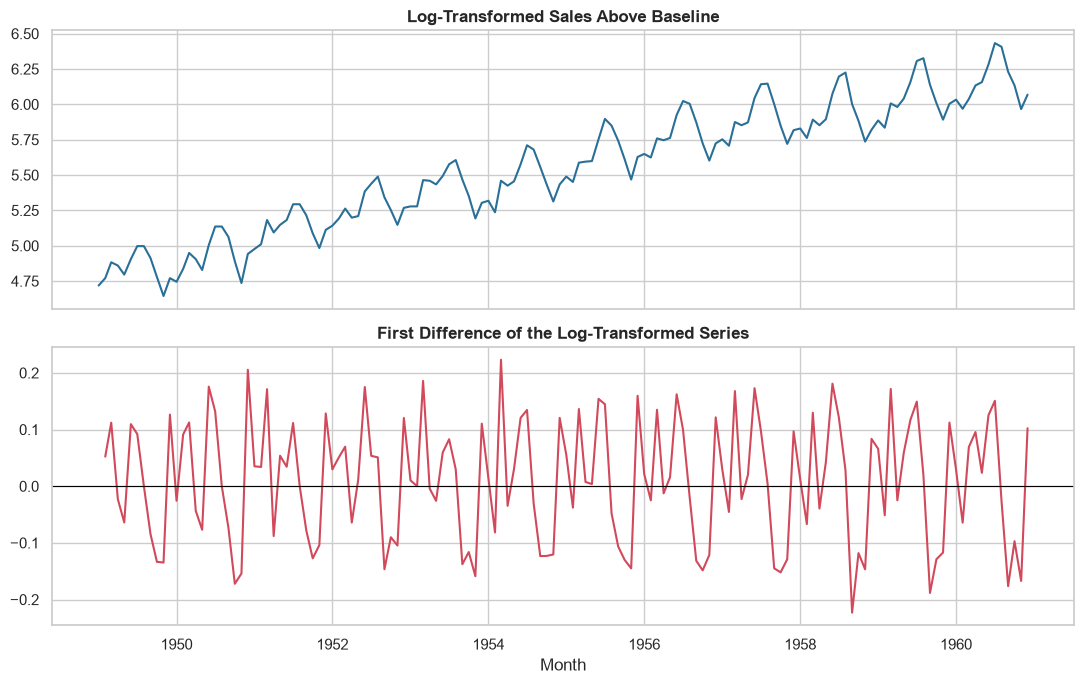

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(log_sales, color="#2A6F97")
axes[0].set_title("Log-Transformed Sales Above Baseline")
axes[1].plot(log_difference, color="#D1495B")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("First Difference of the Log-Transformed Series")
axes[1].set_xlabel("Month")
plt.tight_layout()
plt.show()

The original and log-transformed series both reject the stationarity null. After first differencing, the KPSS p-value is above 0.05, so an integrated model with `d=1` is appropriate.

## 5. Holdout design and model comparison

The last 24 months (1959–1960) are kept as a chronological holdout. Models are trained only through December 1958. This provides a realistic test of forecasting later observations from earlier history.

The seasonal-naive benchmark repeats the most recent 12 months. I first compare several non-seasonal ARIMA `(p, 1, q)` specifications, then test a small set of seasonal ARIMA models because the exploratory analysis showed strong annual seasonality.

In [9]:
holdout_months = 24
train_log = log_sales.iloc[:-holdout_months]
test_actual = y.iloc[-holdout_months:]

seasonal_naive = pd.Series(
    np.tile(y.iloc[-36:-24].to_numpy(), 2),
    index=test_actual.index,
    name="Seasonal naive",
)

arima_rows = []
for order in itertools.product(range(4), [1], range(3)):
    try:
        fitted = ARIMA(train_log, order=order).fit()
        predicted = np.exp(fitted.forecast(holdout_months)) + BASELINE
        arima_rows.append(
            {
                "model": f"ARIMA{order}",
                "order": order,
                "MAE": mean_absolute_error(test_actual, predicted),
                "RMSE": mean_squared_error(test_actual, predicted) ** 0.5,
                "AIC": fitted.aic,
            }
        )
    except (ValueError, np.linalg.LinAlgError):
        continue

arima_results = pd.DataFrame(arima_rows).sort_values("MAE").reset_index(drop=True)
display(arima_results.head(8).round({"MAE": 2, "RMSE": 2, "AIC": 2}))

,model,order,MAE,RMSE,AIC
0,"ARIMA(3, 1, 1)","(3, 1, 1)",79.69,106.31,-206.98
1,"ARIMA(2, 1, 1)","(2, 1, 1)",81.87,107.85,-208.37
2,"ARIMA(3, 1, 2)","(3, 1, 2)",81.94,107.53,-207.70
3,"ARIMA(1, 1, 2)","(1, 1, 2)",86.20,111.41,-206.86
4,"ARIMA(2, 1, 2)","(2, 1, 2)",87.56,112.66,-205.46
5,"ARIMA(0, 1, 2)","(0, 1, 2)",99.41,123.58,-201.16
6,"ARIMA(1, 1, 1)","(1, 1, 1)",101.86,126.16,-201.68
7,"ARIMA(3, 1, 0)","(3, 1, 0)",102.10,125.79,-197.52


In [10]:
seasonal_specs = [
    ((0, 1, 1), (0, 1, 1, 12)),
    ((1, 1, 0), (1, 1, 0, 12)),
    ((1, 1, 1), (0, 1, 1, 12)),
    ((1, 1, 1), (1, 1, 1, 12)),
]

seasonal_rows = []
seasonal_predictions = {}
for order, seasonal_order in seasonal_specs:
    fitted = SARIMAX(
        train_log,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False,
    ).fit(disp=False)
    predicted = np.exp(fitted.forecast(holdout_months)) + BASELINE
    name = f"SARIMA{order}x{seasonal_order}"
    seasonal_predictions[name] = predicted
    seasonal_rows.append(
        {
            "model": name,
            "order": order,
            "seasonal_order": seasonal_order,
            "MAE": mean_absolute_error(test_actual, predicted),
            "RMSE": mean_squared_error(test_actual, predicted) ** 0.5,
            "AIC": fitted.aic,
        }
    )

benchmark_row = {
    "model": "Seasonal naive",
    "order": "repeat prior year",
    "seasonal_order": "12-month cycle",
    "MAE": mean_absolute_error(test_actual, seasonal_naive),
    "RMSE": mean_squared_error(test_actual, seasonal_naive) ** 0.5,
    "AIC": np.nan,
}

comparison = pd.concat(
    [pd.DataFrame([benchmark_row]), pd.DataFrame(seasonal_rows)], ignore_index=True
).sort_values("MAE").reset_index(drop=True)
display(comparison.round({"MAE": 2, "RMSE": 2, "AIC": 2}))

,model,order,seasonal_order,MAE,RMSE,AIC
0,"SARIMA(0, 1, 1)x(0, 1, 1, 12)","(0, 1, 1)","(0, 1, 1, 12)",39.34,43.09,-340.69
1,"SARIMA(1, 1, 1)x(0, 1, 1, 12)","(1, 1, 1)","(0, 1, 1, 12)",42.65,46.39,-339.17
2,"SARIMA(1, 1, 1)x(1, 1, 1, 12)","(1, 1, 1)","(1, 1, 1, 12)",43.85,48.37,-332.62
3,"SARIMA(1, 1, 0)x(1, 1, 0, 12)","(1, 1, 0)","(1, 1, 0, 12)",50.41,55.15,-339.65
4,Seasonal naive,repeat prior year,12-month cycle,71.25,76.99,NaN


The selected model is `SARIMA(0,1,1)(0,1,1,12)`. It has the lowest holdout MAE and clearly improves on both the non-seasonal ARIMA candidates and the seasonal-naive benchmark. The result confirms that annual seasonality is important to this dataset.

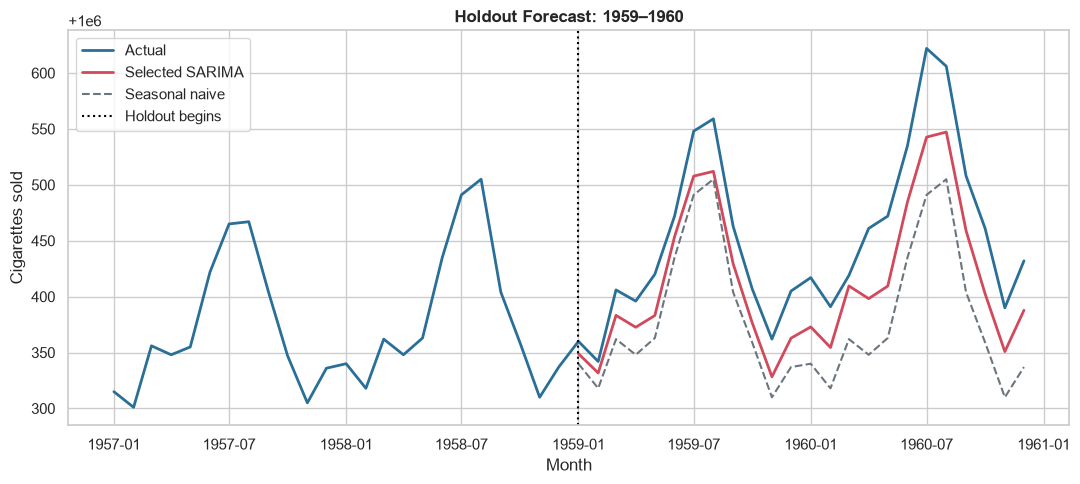

In [11]:
best_name = "SARIMA(0, 1, 1)x(0, 1, 1, 12)"
best_holdout = seasonal_predictions[best_name]

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(y.index[-48:], y.iloc[-48:], label="Actual", color="#2A6F97", linewidth=2)
ax.plot(best_holdout.index, best_holdout, label="Selected SARIMA", color="#D1495B", linewidth=2)
ax.plot(seasonal_naive.index, seasonal_naive, label="Seasonal naive", color="#6C757D", linestyle="--")
ax.axvline(test_actual.index.min(), color="black", linestyle=":", label="Holdout begins")
ax.set(title="Holdout Forecast: 1959–1960", xlabel="Month", ylabel="Cigarettes sold")
ax.ticklabel_format(style="plain", axis="y")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Reconstruct sales for 1961–1963

After model selection, I refit the chosen specification to all observations through December 1960 and forecast the next 36 months. The shaded band is the model's 95% confidence interval.

In [12]:
final_model = SARIMAX(
    log_sales,
    order=(0, 1, 1),
    seasonal_order=(0, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False)

forecast_result = final_model.get_forecast(steps=36)
forecast_mean = np.exp(forecast_result.predicted_mean) + BASELINE
forecast_interval_log = forecast_result.conf_int()
forecast_lower = np.exp(forecast_interval_log.iloc[:, 0]) + BASELINE
forecast_upper = np.exp(forecast_interval_log.iloc[:, 1]) + BASELINE

forecast_table = pd.DataFrame(
    {
        "forecast": forecast_mean,
        "lower_95": forecast_lower,
        "upper_95": forecast_upper,
    }
)
display(forecast_table.head(12).round(1))

,forecast,lower_95,upper_95
1961-01-01,1000450.7,1000419.6,1000484.2
1961-02-01,1000425.9,1000392.2,1000462.4
1961-03-01,1000478.9,1000436.9,1000524.9
1961-04-01,1000492.8,1000445.7,1000544.8
1961-05-01,1000509.5,1000457.2,1000567.8
1961-06-01,1000583.7,1000520.0,1000655.3
1961-07-01,1000670.7,1000593.3,1000758.2
1961-08-01,1000667.6,1000586.8,1000759.7
1961-09-01,1000558.5,1000487.8,1000639.4
1961-10-01,1000497.6,1000432.0,1000573.2


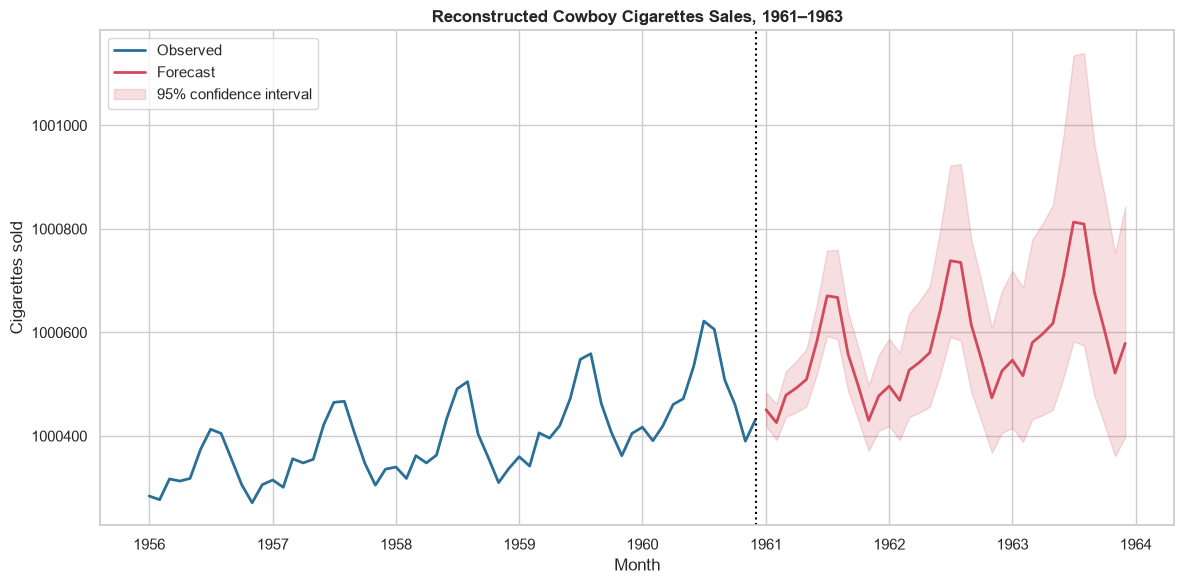

In [13]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(y.index[-60:], y.iloc[-60:], label="Observed", color="#2A6F97", linewidth=2)
ax.plot(forecast_mean.index, forecast_mean, label="Forecast", color="#D1495B", linewidth=2)
ax.fill_between(
    forecast_mean.index,
    forecast_lower.to_numpy(),
    forecast_upper.to_numpy(),
    color="#D1495B",
    alpha=0.18,
    label="95% confidence interval",
)
ax.axvline(y.index.max(), color="black", linestyle=":")
ax.set(title="Reconstructed Cowboy Cigarettes Sales, 1961–1963", xlabel="Month", ylabel="Cigarettes sold")
ax.ticklabel_format(style="plain", axis="y")
ax.legend()
plt.tight_layout()
plt.show()

In [14]:
annual_forecast = forecast_mean.groupby(forecast_mean.index.year).mean().rename("average monthly forecast")
annual_summary = pd.concat(
    [
        pd.Series({1960: y.loc["1960"].mean()}, name="average monthly forecast"),
        annual_forecast,
    ]
).to_frame()
annual_summary["change from prior year"] = annual_summary["average monthly forecast"].diff()
display(annual_summary.round(1))

,average monthly forecast,change from prior year
1960,1000476.2,NaN
1961,1000520.3,44.1
1962,1000572.9,52.6
1963,1000630.9,58.0


## 7. Conclusion

The most probable reconstruction is that Cowboy Cigarettes sales **continued to increase in the early 1960s**, while retaining the same strong annual seasonal cycle. Average monthly sales are forecast to rise from about 1,000,476 in 1960 to roughly 1,000,520 in 1961, 1,000,573 in 1962, and 1,000,631 in 1963.

The holdout test supports using the seasonal model: its MAE is substantially lower than the seasonal-naive benchmark and the non-seasonal ARIMA alternatives. Still, this is a short univariate series. The forecast does not explain *why* sales changed, and it cannot account for policy, marketing, economic conditions, public-health information, or shocks such as conflict. Those factors should be included in a broader causal or multivariate study.